In [1]:
%%capture
%run clean.ipynb
clean_df.head()

In [9]:
# use clean_df as your dataframe

> loading in the .sav file to map countries to their names instead of having numbers

In [2]:
import pyreadstat

sav_path = "../data/Pew Research Center Global Attitudes Spring 2025 Dataset.sav"
_, meta = pyreadstat.read_sav(sav_path, metadataonly=True)

country_names = {int(k): v for k, v in meta.variable_value_labels["country"].items()}
clean_df["country_name"] = clean_df["country"].map(country_names)

## Generation Gap 
Going to show the difference over all of the age ranges, then also compare to 18-29 vs 65+ and see if conclusions differ

Either way need to mention choice in decision log

### Decisions to make and document:
1) **Age groups:** all 4 bands or 18-29 vs 30+ or vs 65+ (does the ranking of largest and smallest gaps stay similar?)
2) **DK/refused:** kept in the total vs dropped from the total
3) **Small groups:** keep but flag any countries with less than 100 and show confidence intervals vs dropping those countries

### Q30
This asks about the respondent's awareness of AI

/var/folders/hq/dqz4020n6jg4g1mm7tshn6sc0000gn/T/ipykernel_1779/1956298076.py:19: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return d.groupby(["country_name", "age_range"]).apply(summarise).reset_index()


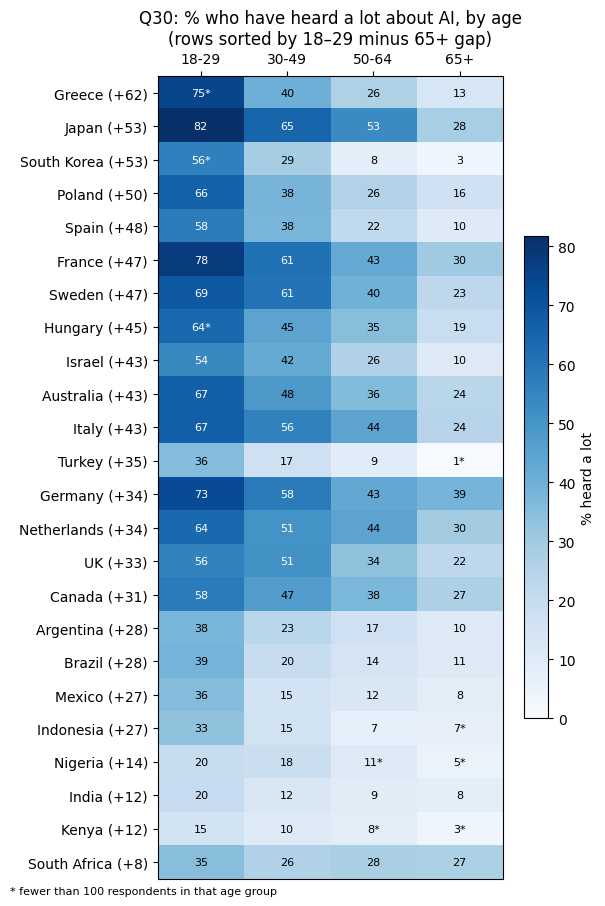

In [ ]:
import matplotlib.pyplot as plt

def band_pct(question, answer, drop_dk=False, weighted=True):
    """Weighted % giving `answer`, per country and age band, with standard error."""
    d = clean_df.dropna(subset=[question, "age_range", "weight"])
    if drop_dk:
        d = d[~d[question].isin([8, 9])]
    d = d.assign(hit=(d[question] == answer).astype(float))

    def summarise(g):
        w = g["weight"] if weighted else pd.Series(1.0, index=g.index)
        p = np.average(g["hit"], weights=w)
        n_eff = w.sum() ** 2 / (w ** 2).sum()          # effective sample size after weighting
        return pd.Series({"pct": 100 * p,
                          "se": 100 * np.sqrt(p * (1 - p) / n_eff),
                          "n": len(g)})
    return d.groupby(["country_name", "age_range"]).apply(summarise).reset_index()

bands = ["18-29", "30-49", "50-64", "65+"]

q30_all = band_pct("ai_heard", 1)                      # 1 = "a lot" (check with meta)
pct = q30_all.pivot(index="country_name", columns="age_range", values="pct")[bands]
n   = q30_all.pivot(index="country_name", columns="age_range", values="n")[bands]

gap_ = (pct["18-29"] - pct["65+"]).sort_values(ascending=False)
pct, n = pct.loc[gap_.index], n.loc[gap_.index]

fig, ax = plt.subplots(figsize=(6, 9))
im = ax.imshow(pct, cmap="Blues", aspect="auto", vmin=0, vmax=pct.values.max())

for i in range(len(pct)):
    for j, b in enumerate(bands):
        val = pct.iloc[i, j]
        star = "*" if n.iloc[i, j] < 100 else ""
        ax.text(j, i, f"{val:.0f}{star}", ha="center", va="center", fontsize=8,
                color="white" if val > pct.values.max() * 0.6 else "black")

ax.set_xticks(range(len(bands)))
ax.set_xticklabels(bands)
ax.xaxis.tick_top()
ax.set_yticks(range(len(pct)))
ax.set_yticklabels([f"{c} ({g:+.0f})" for c, g in gap_.items()])
ax.set_title("Q30: % who have heard a lot about AI, by age\n(rows sorted by 18–29 minus 65+ gap)")
fig.colorbar(im, ax=ax, label="% heard a lot", shrink=0.6)
fig.text(0.01, 0.00, "* fewer than 100 respondents in that age group", fontsize=8)
plt.tight_layout()
#fig.savefig("q30_heatmap.png", dpi=200)

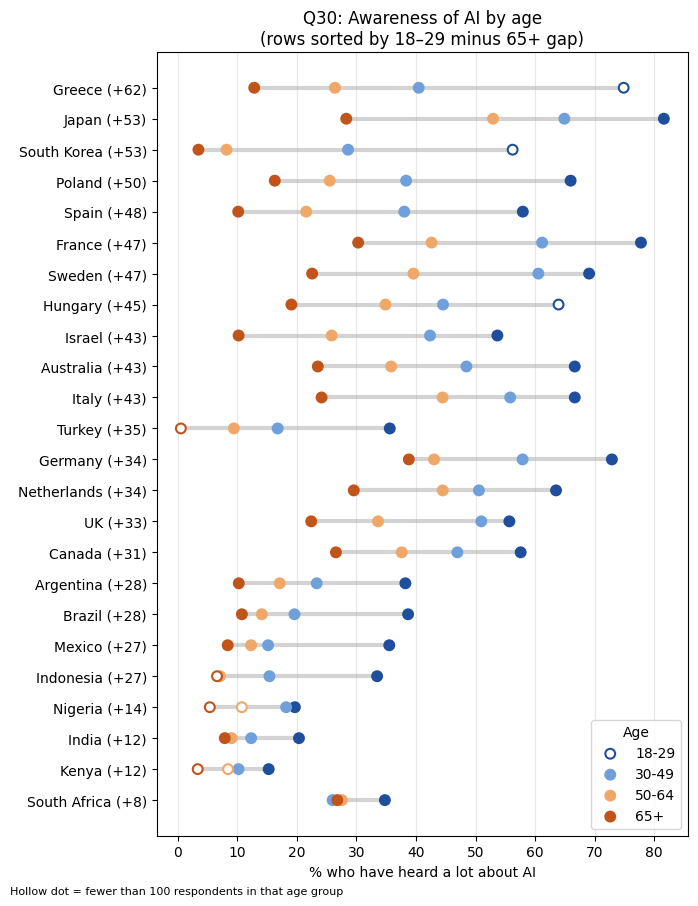

In [ ]:
# dumbbell plot

show = ["18-29", "65+"]
show = bands

colours = {"18-29": "#1f4e9c", "30-49": "#6fa0dc",
           "50-64": "#f0a868", "65+": "#c0541a"}   # blues = younger, oranges = older

fig, ax = plt.subplots(figsize=(7, 9))
y = np.arange(len(pct))

# grey line joining the lowest and highest dot in each row
ax.hlines(y, pct[show].min(axis=1), pct[show].max(axis=1),
          color="lightgrey", lw=3, zorder=1)

for b in show:
    small = (n[b] < 100).values
    # solid dot = 100+ respondents, hollow dot = fewer than 100
    ax.scatter(pct[b], y, s=50, zorder=3, label=b,
               facecolors=np.where(small, "white", colours[b]),
               edgecolors=colours[b], linewidths=1.5)

ax.set_yticks(y)
ax.set_yticklabels([f"{c} ({g:+.0f})" for c, g in gap_.items()])
ax.invert_yaxis()                        # largest gap at the top, same as the heatmap
ax.set_xlabel("% who have heard a lot about AI")
ax.set_title("Q30: Awareness of AI by age\n(rows sorted by 18–29 minus 65+ gap)")
ax.grid(axis="x", alpha=0.3)
ax.legend(title="Age", loc="lower right")
fig.text(0.01, 0.00, "Hollow dot = fewer than 100 respondents in that age group", fontsize=8)
plt.tight_layout()
# fig.savefig(f"q30_dumbbell_{len(show)}bands.png", dpi=200)

### Q31
This asks whether the respondent is more concerned or excited by AI

/var/folders/hq/dqz4020n6jg4g1mm7tshn6sc0000gn/T/ipykernel_1779/1956298076.py:19: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return d.groupby(["country_name", "age_range"]).apply(summarise).reset_index()
/var/folders/hq/dqz4020n6jg4g1mm7tshn6sc0000gn/T/ipykernel_1779/1956298076.py:19: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return d.groupby(["country_name", "age_range"]).apply(summarise).reset_inde

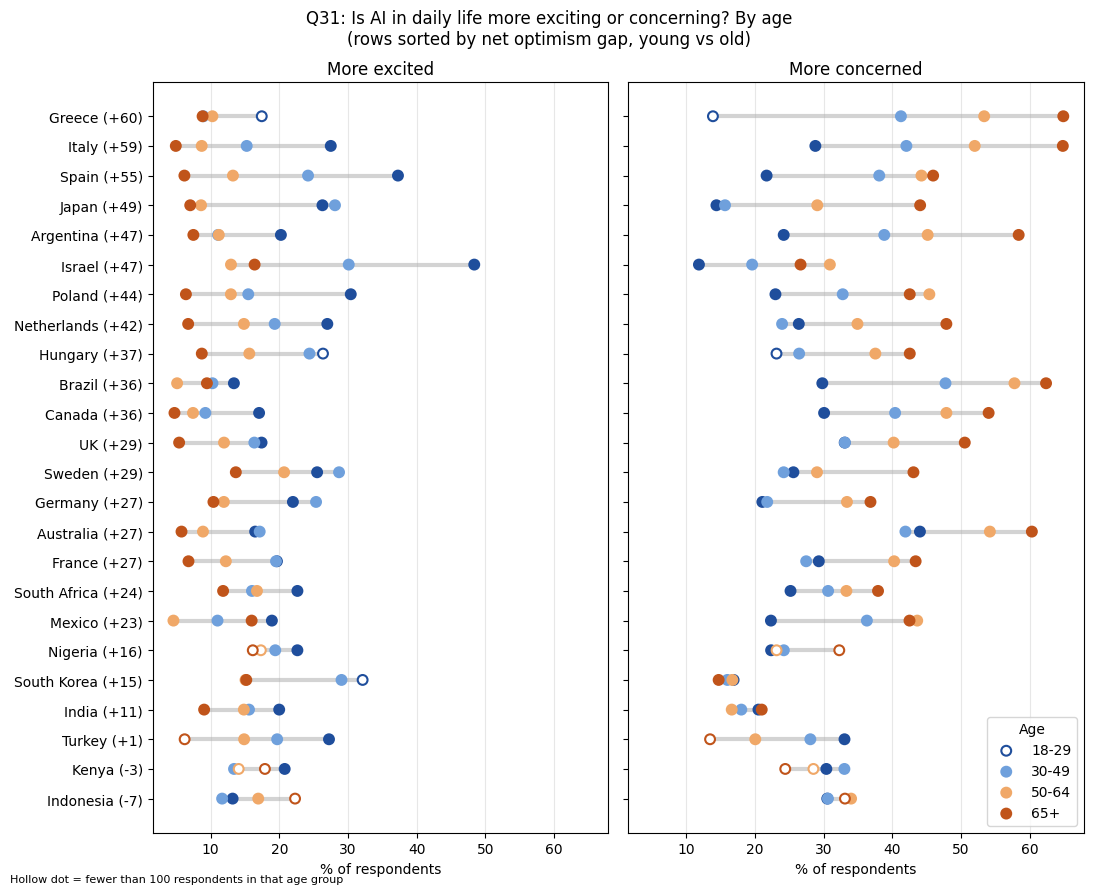

In [8]:
exc = band_pct("ai_cncexc", 1)
con = band_pct("ai_cncexc", 2)
exc_p = exc.pivot(index="country_name", columns="age_range", values="pct")[bands]
con_p = con.pivot(index="country_name", columns="age_range", values="pct")[bands]
n31   = exc.pivot(index="country_name", columns="age_range", values="n")[bands]

net_gap = ((exc_p["18-29"] - con_p["18-29"]) - (exc_p["65+"] - con_p["65+"])).sort_values(ascending=False)
order = net_gap.index

fig, axes = plt.subplots(1, 2, figsize=(11, 9), sharey=True, sharex=True)
y = np.arange(len(order))

for ax, data, title in [(axes[0], exc_p, "More excited"), (axes[1], con_p, "More concerned")]:
    d = data.loc[order]
    ax.hlines(y, d[show].min(axis=1), d[show].max(axis=1), color="lightgrey", lw=3, zorder=1)
    for b in show:
        small = (n31.loc[order, b] < 100).values
        ax.scatter(d[b], y, s=50, zorder=3, label=b,
                   facecolors=np.where(small, "white", colours[b]),
                   edgecolors=colours[b], linewidths=1.5)
    ax.set_title(title)
    ax.set_xlabel("% of respondents")
    ax.grid(axis="x", alpha=0.3)

axes[0].set_yticks(y)
axes[0].set_yticklabels([f"{c} ({g:+.0f})" for c, g in net_gap.items()])
axes[0].invert_yaxis()
axes[1].legend(title="Age", loc="lower right")
fig.suptitle("Q31: Is AI in daily life more exciting or concerning? By age\n"
             "(rows sorted by net optimism gap, young vs old)")
fig.text(0.01, 0.01, "Hollow dot = fewer than 100 respondents in that age group", fontsize=8)
plt.tight_layout()
#fig.savefig("q31_dumbbell_side_by_side.png", dpi=200)

/var/folders/hq/dqz4020n6jg4g1mm7tshn6sc0000gn/T/ipykernel_1779/2823751223.py:15: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  out = d.groupby(["country_name", "age_group"]).apply(
/var/folders/hq/dqz4020n6jg4g1mm7tshn6sc0000gn/T/ipykernel_1779/2823751223.py:15: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  out = d.groupby(["country_name", "age_group"]).apply(


Young MORE excited in 23 of 24 countries
Young LESS concerned in 21 of 24 countries
Both at once in 20 countries
Largest net gap: Greece 59.6
Smallest net gap: Turkey 1.4


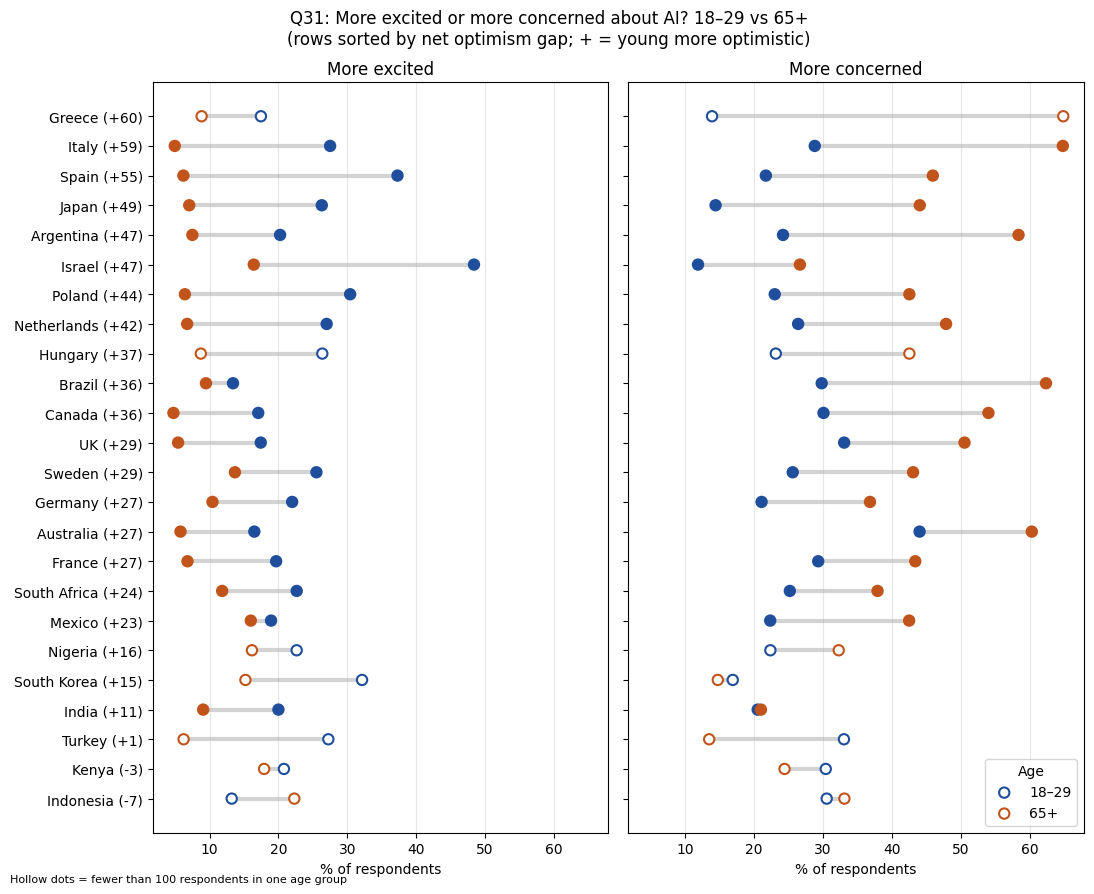

In [9]:
# ---- 1. Define young vs old (change this line for the alternative) ----
age_groups = {"18-29": "Young", "65+": "Old"}
# Alternative for the decision log: old = 50+ (bigger groups)
# age_groups = {"18-29": "Young", "50-64": "Old", "65+": "Old"}

clean_df["age_group"] = clean_df["age_range"].map(age_groups)
old_label = "65+" if len(age_groups) == 2 else "50+"

# ---- 2. Weighted % per country and group ----
def group_pct(question, answer, drop_dk=False):
    d = clean_df.dropna(subset=[question, "age_group", "weight"])
    if drop_dk:
        d = d[~d[question].isin([8, 9])]
    d = d.assign(hit=(d[question] == answer).astype(float))
    out = d.groupby(["country_name", "age_group"]).apply(
        lambda g: pd.Series({"pct": 100 * np.average(g["hit"], weights=g["weight"]),
                             "n": len(g)})
    ).reset_index()
    return out.pivot(index="country_name", columns="age_group")

exc = group_pct("ai_cncexc", 1)    # more excited
con = group_pct("ai_cncexc", 2)    # more concerned

exc_gap = exc[("pct", "Young")] - exc[("pct", "Old")]
con_gap = con[("pct", "Young")] - con[("pct", "Old")]
net_gap = (exc_gap - con_gap).sort_values(ascending=False)
order = net_gap.index

small = (exc["n"].min(axis=1) < 100).loc[order].values   # either group under 100

# ---- 3. Plot ----
colours = {"Young": "#1f4e9c", "Old": "#c0541a"}
fig, axes = plt.subplots(1, 2, figsize=(11, 9), sharey=True, sharex=True)
y = np.arange(len(order))

for ax, data, title in [(axes[0], exc, "More excited"), (axes[1], con, "More concerned")]:
    young = data[("pct", "Young")].loc[order]
    old   = data[("pct", "Old")].loc[order]
    ax.hlines(y, np.minimum(young, old), np.maximum(young, old),
              color="lightgrey", lw=3, zorder=1)
    for label, vals in [("Young", young), ("Old", old)]:
        ax.scatter(vals, y, s=55, zorder=3,
                   label=f"18–29" if label == "Young" else old_label,
                   facecolors=np.where(small, "white", colours[label]),
                   edgecolors=colours[label], linewidths=1.5)
    ax.set_title(title)
    ax.set_xlabel("% of respondents")
    ax.grid(axis="x", alpha=0.3)

axes[0].set_yticks(y)
axes[0].set_yticklabels([f"{c} ({g:+.0f})" for c, g in net_gap.items()])
axes[0].invert_yaxis()
axes[1].legend(title="Age", loc="lower right")
fig.suptitle(f"Q31: More excited or more concerned about AI? 18–29 vs {old_label}\n"
             "(rows sorted by net optimism gap; + = young more optimistic)")
fig.text(0.01, 0.01, "Hollow dots = fewer than 100 respondents in one age group", fontsize=8)
plt.tight_layout()
#fig.savefig(f"q31_young_vs_{old_label.replace('+', 'plus')}.png", dpi=200)

# ---- 4. Numbers for the conclusions ----
print("Young MORE excited in", (exc_gap > 0).sum(), "of", len(exc_gap), "countries")
print("Young LESS concerned in", (con_gap < 0).sum(), "of", len(con_gap), "countries")
print("Both at once in", ((exc_gap > 0) & (con_gap < 0)).sum(), "countries")
print("Largest net gap:", net_gap.idxmax(), round(net_gap.max(), 1))
print("Smallest net gap:", net_gap.abs().idxmin(), round(net_gap.abs().min(), 1))